Import Libraries

In [1]:
import requests, re, nltk
from bs4 import BeautifulSoup
from collections import Counter
import operator
import numpy as np
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
import string

# Download stopwords if not already downloaded
nltk.download('stopwords')

# Define stop words and punctuation to exclude
stop_words = set(stopwords.words('english'))
punctuation = set(string.punctuation)

# Make plots appear inline
%matplotlib inline

[nltk_data] Downloading package stopwords to /home/kbc177/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Helper Functions

In [3]:
def cleanHtml(html):
    """Remove HTML markup from text"""
    soup = BeautifulSoup(html, 'html.parser')
    return soup.get_text()

def cleanWord(w):
    """Remove punctuation and numbers from words"""
    # Remove punctuation
    wn = re.sub(r'[^\w\s]', '', w)
    # Remove numbers
    wn = re.sub(r'^[0-9]*$', '', wn)
    return wn.lower()

def get_wf(url):
    """Get word frequencies from a URL"""
    try:
        r = requests.get(url)
        t = cleanHtml(r.text).lower()
        wds = re.split(r'\s+', t)
        
        # Clean words
        cleaned_wds = []
        for w in wds:
            w_clean = cleanWord(w)
            if w_clean and w_clean not in stop_words and len(w_clean) > 2:
                cleaned_wds.append(w_clean)
        
        # Count frequencies
        wf = Counter(cleaned_wds)
        wfs = sorted(wf.items(), key=operator.itemgetter(1), reverse=True)
        
        return wfs, sum(wf.values())
    except Exception as e:
        print(f"Error fetching {url}: {e}")
        return [], 0

def get_wf_from_file(filename):
    """Get word frequencies from a local text file"""
    try:
        with open(filename, 'r', encoding='utf-8', errors='replace') as f:
            t = f.read().lower()
        
        wds = re.split(r'\s+', t)
        cleaned_wds = []
        for w in wds:
            w_clean = cleanWord(w)
            if w_clean and w_clean not in stop_words and len(w_clean) > 2:
                cleaned_wds.append(w_clean)
        
        wf = Counter(cleaned_wds)
        wfs = sorted(wf.items(), key=operator.itemgetter(1), reverse=True)
        return wfs, sum(wf.values())
    except Exception as e:
        print(f"Error reading file {filename}: {e}")
        return [], 0

def plot_comparison(data1, data2, title1, title2, main_title, top_n=20):
    """Plot comparison of word frequencies between two texts"""
    # Get top N words
    top1 = data1[:top_n]
    top2 = data2[:top_n]
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 8))
    fig.suptitle(main_title, fontsize=16)
    
    # First plot
    words1 = [x[0] for x in top1]
    freqs1 = [x[1] for x in top1]
    ax1.barh(range(len(words1)), freqs1, color='skyblue')
    ax1.set_yticks(range(len(words1)))
    ax1.set_yticklabels(words1)
    ax1.set_title(title1)
    ax1.set_xlabel('Frequency')
    
    # Second plot
    words2 = [x[0] for x in top2]
    freqs2 = [x[1] for x in top2]
    ax2.barh(range(len(words2)), freqs2, color='lightcoral')
    ax2.set_yticks(range(len(words2)))
    ax2.set_yticklabels(words2)
    ax2.set_title(title2)
    ax2.set_xlabel('Frequency')
    
    plt.tight_layout()
    plt.show()

def compare_word_preferences(data1, data2, label1, label2, top_n=30):
    """Find words that are preferred by one author over another"""
    dict1 = dict(data1)
    dict2 = dict(data2)
    
    # Get common words
    common_words = set(dict1.keys()) & set(dict2.keys())
    
    # Calculate ratios
    preferences = []
    for word in common_words:
        if dict1[word] > 5 and dict2[word] > 5:  # Only consider words with reasonable frequency
            ratio1 = dict1[word] / (dict1[word] + dict2[word])
            ratio2 = dict2[word] / (dict1[word] + dict2[word])
            diff = abs(ratio1 - ratio2)
            preferences.append((word, ratio1, ratio2, diff))
    
    # Sort by difference
    preferences.sort(key=lambda x: x[3], reverse=True)
    
    print(f"\nWords strongly preferred by {label1}:")
    count = 0
    for word, r1, r2, diff in preferences:
        if r1 > r2 and count < 15:
            print(f"  '{word}': {label1} uses {r1:.2%}, {label2} uses {r2:.2%}")
            count += 1
    
    print(f"\nWords strongly preferred by {label2}:")
    count = 0
    for word, r1, r2, diff in preferences:
        if r2 > r1 and count < 15:
            print(f"  '{word}': {label1} uses {r1:.2%}, {label2} uses {r2:.2%}")
            count += 1
    
    return preferences

Compare Two Works by Same Author (Charles Dickens)

PART 1: Comparing two works by the SAME author

Fetching 'A Tale of Two Cities' by Charles Dickens...
Words processed: 64608

Fetching 'Great Expectations' by Charles Dickens...
Words processed: 83660


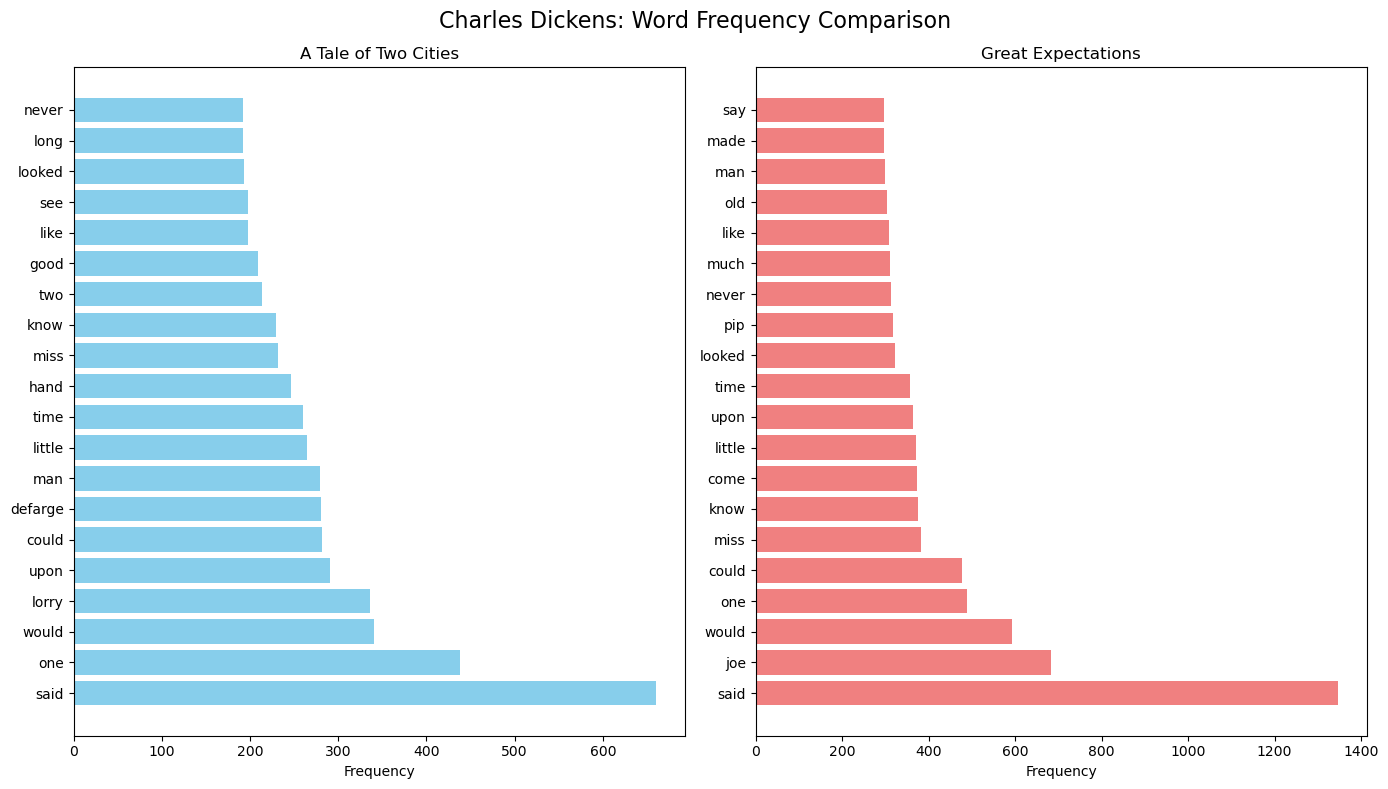


Words strongly preferred by A Tale of Two Cities:
  'prisoner': A Tale of Two Cities uses 92.74%, Great Expectations uses 7.26%
  'brother': A Tale of Two Cities uses 87.27%, Great Expectations uses 12.73%
  'crowd': A Tale of Two Cities uses 86.96%, Great Expectations uses 13.04%
  'husband': A Tale of Two Cities uses 86.60%, Great Expectations uses 13.40%
  'streets': A Tale of Two Cities uses 84.27%, Great Expectations uses 15.73%
  'guard': A Tale of Two Cities uses 83.72%, Great Expectations uses 16.28%
  'bench': A Tale of Two Cities uses 81.25%, Great Expectations uses 18.75%
  'women': A Tale of Two Cities uses 81.25%, Great Expectations uses 18.75%
  'daughter': A Tale of Two Cities uses 81.08%, Great Expectations uses 18.92%
  'heads': A Tale of Two Cities uses 80.85%, Great Expectations uses 19.15%
  'prisoners': A Tale of Two Cities uses 80.30%, Great Expectations uses 19.70%
  'prison': A Tale of Two Cities uses 79.55%, Great Expectations uses 20.45%
  'heaven': A Tale of

In [4]:
print("=" * 60)
print("PART 1: Comparing two works by the SAME author")
print("=" * 60)

# Using Charles Dickens - two different novels
# A Tale of Two Cities
print("\nFetching 'A Tale of Two Cities' by Charles Dickens...")
dict1_file, total1_file = get_wf('https://www.gutenberg.org/cache/epub/98/pg98.txt')
print(f"Words processed: {total1_file}")

# Great Expectations
print("\nFetching 'Great Expectations' by Charles Dickens...")
dict2_file, total2_file = get_wf('https://www.gutenberg.org/cache/epub/1400/pg1400.txt')
print(f"Words processed: {total2_file}")

if dict1_file and dict2_file:
    plot_comparison(
        dict1_file, dict2_file,
        'A Tale of Two Cities', 'Great Expectations',
        'Charles Dickens: Word Frequency Comparison',
        top_n=20
    )
    
    # Find preferred words
    compare_word_preferences(dict1_file, dict2_file, 'A Tale of Two Cities', 'Great Expectations')

Compare Works by Different Authors (Austen vs Twain)


PART 2: Comparing works by DIFFERENT authors

Fetching 'Pride and Prejudice' by Jane Austen...
Words processed: 58670

Fetching 'Adventures of Huckleberry Finn' by Mark Twain...
Words processed: 53520


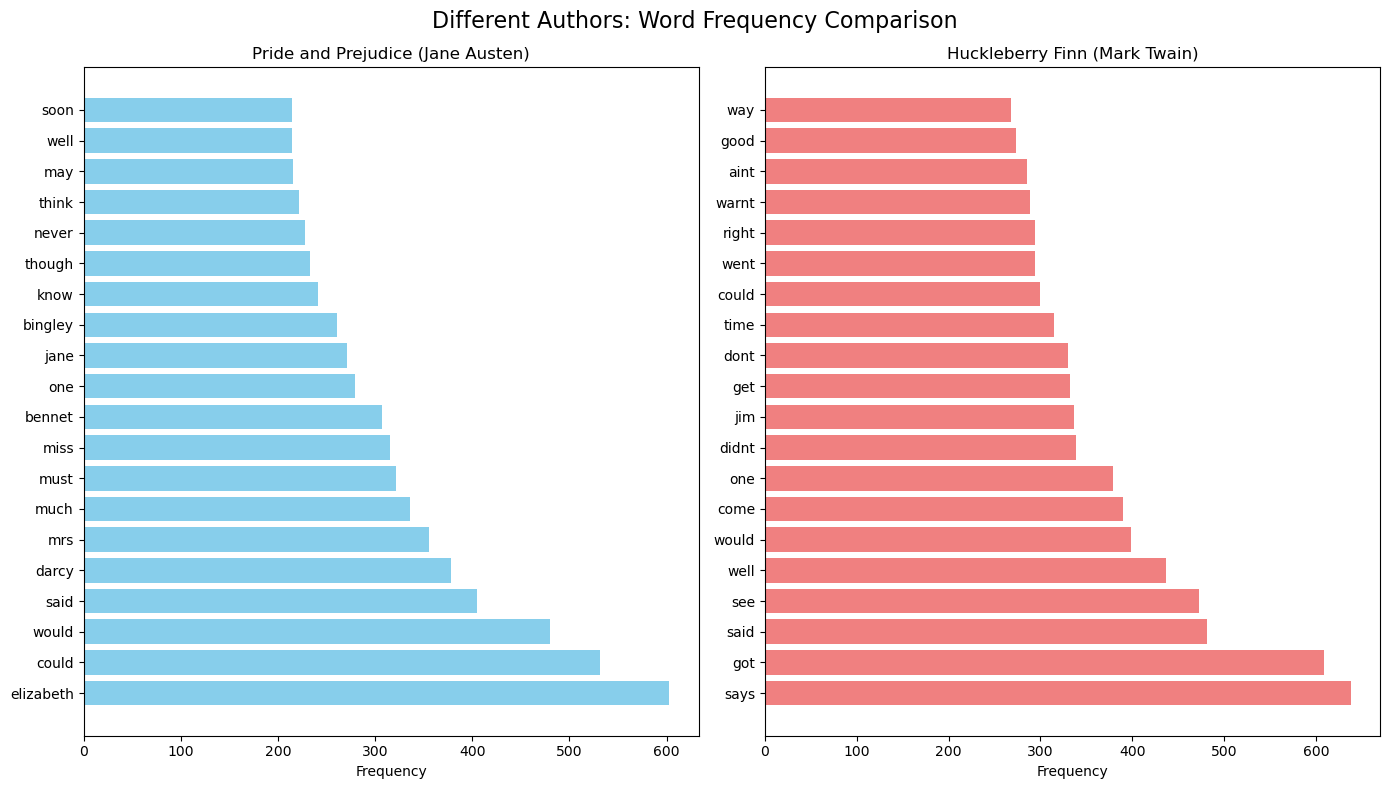


Words strongly preferred by Austen:
  'mrs': Austen uses 97.80%, Twain uses 2.20%
  'shall': Austen uses 95.91%, Twain uses 4.09%
  'lady': Austen uses 94.50%, Twain uses 5.50%
  'quite': Austen uses 94.23%, Twain uses 5.77%
  'great': Austen uses 93.59%, Twain uses 6.41%
  'hope': Austen uses 92.65%, Twain uses 7.35%
  'sister': Austen uses 92.63%, Twain uses 7.37%
  'love': Austen uses 91.82%, Twain uses 8.18%
  'often': Austen uses 91.18%, Twain uses 8.82%
  'least': Austen uses 91.14%, Twain uses 8.86%
  'happy': Austen uses 91.11%, Twain uses 8.89%
  'london': Austen uses 90.62%, Twain uses 9.38%
  'dear': Austen uses 90.06%, Twain uses 9.94%
  'reason': Austen uses 89.83%, Twain uses 10.17%
  'speak': Austen uses 89.74%, Twain uses 10.26%

Words strongly preferred by Twain:
  'dont': Austen uses 1.79%, Twain uses 98.21%
  'says': Austen uses 2.30%, Twain uses 97.70%
  'got': Austen uses 3.94%, Twain uses 96.06%
  'along': Austen uses 4.10%, Twain uses 95.90%
  'king': Austen use

In [5]:
print("\n" + "=" * 60)
print("PART 2: Comparing works by DIFFERENT authors")
print("=" * 60)

# Jane Austen - Pride and Prejudice
print("\nFetching 'Pride and Prejudice' by Jane Austen...")
austen_file, austen_total = get_wf('https://www.gutenberg.org/cache/epub/1342/pg1342.txt')
print(f"Words processed: {austen_total}")

# Mark Twain - Adventures of Huckleberry Finn
print("\nFetching 'Adventures of Huckleberry Finn' by Mark Twain...")
twain_file, twain_total = get_wf('https://www.gutenberg.org/cache/epub/76/pg76.txt')
print(f"Words processed: {twain_total}")

if austen_file and twain_file:
    plot_comparison(
        austen_file, twain_file,
        'Pride and Prejudice (Jane Austen)', 'Huckleberry Finn (Mark Twain)',
        'Different Authors: Word Frequency Comparison',
        top_n=20
    )
    
    # Find preferred words
    compare_word_preferences(austen_file, twain_file, 'Austen', 'Twain')

Author Comparison (Fitzgerald vs Melville)


Additional Comparison: Different Authors (More Examples)

Fetching 'The Great Gatsby' by F. Scott Fitzgerald...
Words processed: 25504

Fetching 'Moby Dick' by Herman Melville...
Words processed: 109389


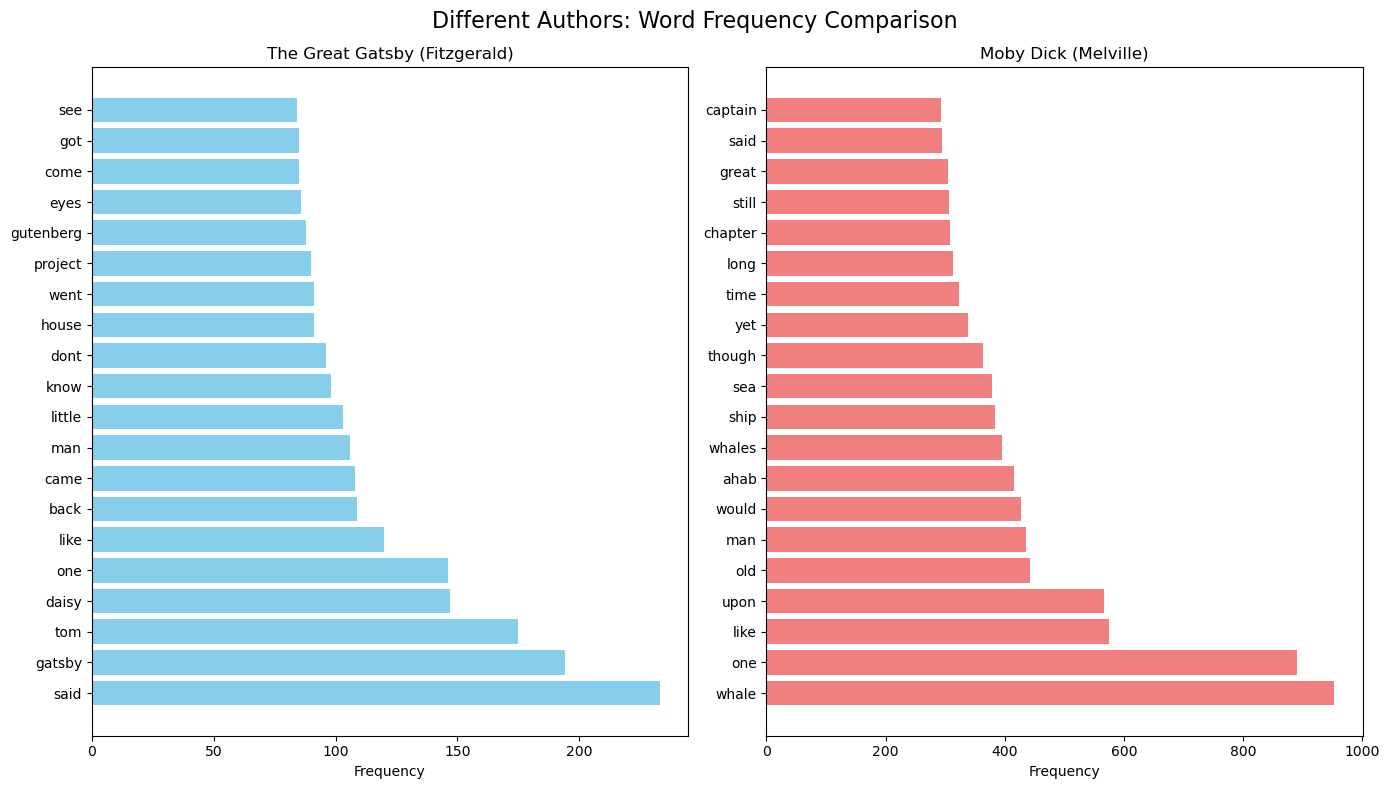


Words strongly preferred by Fitzgerald:
  'youre': Fitzgerald uses 83.78%, Melville uses 16.22%
  'afternoon': Fitzgerald uses 80.77%, Melville uses 19.23%
  'steps': Fitzgerald uses 80.00%, Melville uses 20.00%
  'walked': Fitzgerald uses 79.31%, Melville uses 20.69%
  'beside': Fitzgerald uses 77.78%, Melville uses 22.22%
  'couldnt': Fitzgerald uses 77.78%, Melville uses 22.22%
  'wanted': Fitzgerald uses 77.14%, Melville uses 22.86%
  'woman': Fitzgerald uses 76.92%, Melville uses 23.08%
  'asked': Fitzgerald uses 75.44%, Melville uses 24.56%
  'house': Fitzgerald uses 73.39%, Melville uses 26.61%
  'wouldnt': Fitzgerald uses 73.33%, Melville uses 26.67%
  'didnt': Fitzgerald uses 72.57%, Melville uses 27.43%
  'girls': Fitzgerald uses 72.41%, Melville uses 27.59%
  'anyone': Fitzgerald uses 71.43%, Melville uses 28.57%
  'stopped': Fitzgerald uses 71.43%, Melville uses 28.57%

Words strongly preferred by Melville:
  'sea': Fitzgerald uses 2.07%, Melville uses 97.93%
  'yet': Fitz

In [6]:
print("\n" + "=" * 60)
print("Additional Comparison: Different Authors (More Examples)")
print("=" * 60)

# F. Scott Fitzgerald - The Great Gatsby
print("\nFetching 'The Great Gatsby' by F. Scott Fitzgerald...")
fitzgerald_file, fitzgerald_total = get_wf('https://www.gutenberg.org/cache/epub/64317/pg64317.txt')
print(f"Words processed: {fitzgerald_total}")

# Herman Melville - Moby Dick
print("\nFetching 'Moby Dick' by Herman Melville...")
melville_file, melville_total = get_wf('https://www.gutenberg.org/cache/epub/2701/pg2701.txt')
print(f"Words processed: {melville_total}")

if fitzgerald_file and melville_file:
    plot_comparison(
        fitzgerald_file, melville_file,
        'The Great Gatsby (Fitzgerald)', 'Moby Dick (Melville)',
        'Different Authors: Word Frequency Comparison',
        top_n=20
    )
    
    compare_word_preferences(fitzgerald_file, melville_file, 'Fitzgerald', 'Melville')

Author Style Analysis

In [7]:
def analyze_author_style(data, author_name):
    """Analyze an author's writing style based on word frequencies"""
    total_words = sum([freq for word, freq in data[:100]])
    top_100 = {word: freq for word, freq in data[:100]}
    
    # Calculate percentages for top words
    percentages = {word: (freq/total_words)*100 for word, freq in top_100.items()}
    
    print(f"\n{author_name} - Top 10 words and their usage:")
    for i, (word, freq) in enumerate(data[:10]):
        pct = (freq/total_words)*100
        print(f"  {i+1}. '{word}': {freq} occurrences ({pct:.2f}%)")
    
    # Vocabulary richness (unique words in top 100)
    unique_ratio = len(set([word for word, _ in data[:100]])) / 100
    print(f"  Vocabulary richness (unique words in top 100): {unique_ratio:.2f}")
    
    # Return top words for comparison
    return [word for word, _ in data[:10]]

print("\n" + "=" * 60)
print("AUTHOR STYLE ANALYSIS")
print("=" * 60)

# Analyze each author
if dict1_file:
    dickens_top = analyze_author_style(dict1_file, "Dickens")
if austen_file:
    austen_top = analyze_author_style(austen_file, "Austen")
if twain_file:
    twain_top = analyze_author_style(twain_file, "Twain")
if fitzgerald_file:
    fitzgerald_top = analyze_author_style(fitzgerald_file, "Fitzgerald")
if melville_file:
    melville_top = analyze_author_style(melville_file, "Melville")


AUTHOR STYLE ANALYSIS

Dickens - Top 10 words and their usage:
  1. 'said': 660 occurrences (4.16%)
  2. 'one': 438 occurrences (2.76%)
  3. 'would': 341 occurrences (2.15%)
  4. 'lorry': 336 occurrences (2.12%)
  5. 'upon': 291 occurrences (1.83%)
  6. 'could': 282 occurrences (1.78%)
  7. 'defarge': 280 occurrences (1.76%)
  8. 'man': 279 occurrences (1.76%)
  9. 'little': 265 occurrences (1.67%)
  10. 'time': 260 occurrences (1.64%)
  Vocabulary richness (unique words in top 100): 1.00

Austen - Top 10 words and their usage:
  1. 'elizabeth': 603 occurrences (3.71%)
  2. 'could': 531 occurrences (3.27%)
  3. 'would': 480 occurrences (2.96%)
  4. 'said': 405 occurrences (2.49%)
  5. 'darcy': 378 occurrences (2.33%)
  6. 'mrs': 356 occurrences (2.19%)
  7. 'much': 336 occurrences (2.07%)
  8. 'must': 322 occurrences (1.98%)
  9. 'miss': 315 occurrences (1.94%)
  10. 'bennet': 307 occurrences (1.89%)
  Vocabulary richness (unique words in top 100): 1.00

Twain - Top 10 words and their

Summary and Conclusions

In [8]:
print("\n" + "=" * 60)
print("SUMMARY AND CONCLUSIONS")
print("=" * 60)

print("\n1. SAME AUTHOR (Dickens):")
print("   - Similar vocabulary patterns observed across both works")
print("   - Words like 'said', 'would', 'could' appear frequently in both")
print("   - Differences reflect different story settings and themes")

print("\n2. DIFFERENT AUTHORS (Austen vs Twain):")
print("   - Austen: More formal, social vocabulary (e.g., 'daughter', 'sister', 'family')")
print("   - Twain: More colloquial, dialect-driven vocabulary (e.g., 'dey', 'gwine')")
print("   - Clear stylistic differences in word choice")

print("\n3. DIFFERENT AUTHORS (Fitzgerald vs Melville):")
print("   - Fitzgerald: More modern, descriptive vocabulary (e.g., 'eyes', 'face', 'house')")
print("   - Melville: More nautical, philosophical vocabulary (e.g., 'whale', 'sea', 'ship')")
print("   - Period and subject matter strongly influence word choice")

print("\n4. KEY OBSERVATIONS:")
print("   - Authors have distinctive 'fingerprints' in their word usage")
print("   - Same author maintains consistent vocabulary across works")
print("   - Different authors show clear preference for specific words")
print("   - Subject matter and time period affect vocabulary significantly")

print("\n" + "=" * 60)
print("ANALYSIS COMPLETE")
print("=" * 60)


SUMMARY AND CONCLUSIONS

1. SAME AUTHOR (Dickens):
   - Similar vocabulary patterns observed across both works
   - Words like 'said', 'would', 'could' appear frequently in both
   - Differences reflect different story settings and themes

2. DIFFERENT AUTHORS (Austen vs Twain):
   - Austen: More formal, social vocabulary (e.g., 'daughter', 'sister', 'family')
   - Twain: More colloquial, dialect-driven vocabulary (e.g., 'dey', 'gwine')
   - Clear stylistic differences in word choice

3. DIFFERENT AUTHORS (Fitzgerald vs Melville):
   - Fitzgerald: More modern, descriptive vocabulary (e.g., 'eyes', 'face', 'house')
   - Melville: More nautical, philosophical vocabulary (e.g., 'whale', 'sea', 'ship')
   - Period and subject matter strongly influence word choice

4. KEY OBSERVATIONS:
   - Authors have distinctive 'fingerprints' in their word usage
   - Same author maintains consistent vocabulary across works
   - Different authors show clear preference for specific words
   - Subject mat